# Tarea 03: Generación de imágenes con autoencoders
### PyTorch Lightning · Hydra · Weights & Biases

**Curso:** Inteligencia Artificial — Escuela de Ingeniería en Computación, Instituto Tecnológico de Costa Rica

**Integrantes:**
- Sebastián Chacón - 2023221908
- Daniel Pulido - 2019196502
- Sebastián Muñoz - 2023090681

**Objetivo:** comparar un *Variational Autoencoder* (VAE) y un autoencoder U-Net (con *skip connections*) en la reconstrucción de imágenes de MVTec AD, entrenando cada uno con cuatro funciones de pérdida (L1, L2, SSIM y SSIM + L1) y analizando su capacidad para distinguir imágenes normales de imágenes con anomalías.

> Todas las figuras de resultados de este notebook se generan y registran en Weights & Biases y luego se insertan aquí (descargándolas con la API de W&B).

## Contenido
1. Configuración del entorno
2. Dataset (MVTec AD)
3. Configuración de experimentos con Hydra
4. Modelos
5. Funciones de pérdida
6. Entrenamiento (trials de hiperparámetros, sin repetir corridas)
7. Seguimiento de los entrenamientos en W&B
8. Evaluación del modelo
9. Comparación entre configuraciones
10. Conclusiones

## 1. Configuración del entorno

### 1.1 Entorno virtual (`.venv`)
El proyecto usa un entorno virtual propio con **Python 3.11** (Hydra y Lightning son más estables en 3.11 que en 3.14). Se crea **una sola vez** desde una terminal en la raíz del repositorio, antes de abrir el notebook, porque el notebook tiene que ejecutarse *dentro* de ese entorno:

```powershell
py -3.11 -m venv .venv
.venv\Scripts\python -m pip install --upgrade pip
# PyTorch con CUDA (GPU NVIDIA). Sin GPU: quitar --index-url para instalar la versión CPU
.venv\Scripts\python -m pip install torch torchvision --index-url https://download.pytorch.org/whl/cu130
.venv\Scripts\python -m pip install -r requirements.txt
# Registrar el entorno como kernel de Jupyter
.venv\Scripts\python -m ipykernel install --user --name autoencoder --display-name "Python (.venv Autoencoder)"
```

Luego, en VS Code: **Select Kernel → Python Environments → `.venv`** (o el kernel *Python (.venv Autoencoder)* en Jupyter).
La siguiente celda verifica que el notebook esté corriendo con el Python del `.venv`, imprime las versiones y si hay GPU.

### 1.2 Imports, versiones y directorio de trabajo
El notebook vive en `notebooks/`, pero `train.py`, `conf/` y `data/` usan rutas relativas a la raíz del repositorio, así que se cambia el directorio de trabajo a la raíz.

In [1]:
# Imports, versiones de librerías, GPU y directorio de trabajo
import os
import sys
from pathlib import Path

# The notebook lives in notebooks/; train.py, conf/ and data/ are relative to the repo root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import logging
import warnings

# Hide noise that does not affect the results: torch's "triton not found" (no triton on Windows) and deprecation notices
logging.getLogger("torch.utils.flop_counter").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

import hydra
import lightning as L
import pandas as pd
import plotly
import torch
import torchmetrics
import torchvision
import wandb
from omegaconf import OmegaConf
from IPython.display import Image, display

print("Raíz del repo:", ROOT)
print("Python       :", sys.executable)
if ".venv" not in sys.executable:
    print("ADVERTENCIA: el kernel no es el del .venv (ver 1.1)")
for name, module in [("torch", torch), ("torchvision", torchvision), ("lightning", L), ("hydra-core", hydra),
                     ("wandb", wandb), ("torchmetrics", torchmetrics), ("plotly", plotly), ("pandas", pd)]:
    print(f"{name:<13}: {module.__version__}")
print("GPU          :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no disponible (CPU)")

Raíz del repo: c:\Users\Chaco\OneDrive\Documents\GitHub\Autoencoder
Python       : c:\Users\Chaco\OneDrive\Documents\GitHub\Autoencoder\.venv\Scripts\python.exe
torch        : 2.14.1+cu130
torchvision  : 0.29.1+cu130
lightning    : 2.6.6
hydra-core   : 1.3.8
wandb        : 0.31.0
torchmetrics : 1.9.0
plotly       : 7.1.0
pandas       : 3.1.0
GPU          : NVIDIA GeForce RTX 4060


### 1.3 Weights & Biases
Todos los experimentos se registran en el **team** de W&B del grupo ([danielpulido-instituto-tecnol-gico-de-costa-rica](https://forge.coreweave.com/wandb/danielpulido-instituto-tecnol-gico-de-costa-rica/members)), proyecto `Autoencoder`, ambos definidos en `conf/logger/wandb.yaml`. **Cada integrante inicia sesión con su propia cuenta** (su propia API key) y, como todos pertenecen al team, las corridas de todos quedan en el mismo proyecto, firmadas con el usuario que las lanzó. Cada corrida se llama `<modelo>-<pérdida>-<trial>` (por ejemplo `vae-ssim_l1-e200`; ver 6.1), se agrupa por modelo, lleva como tags el modelo, la pérdida y el trial y guarda la configuración completa de Hydra. Durante el entrenamiento se registran:

| Clave en W&B | Contenido |
|---|---|
| `train/loss`, `val/loss` | pérdida de entrenamiento y validación por época (la función de pérdida de la corrida + β·KL en el VAE) |
| `train/l1`, `val/mse`, `val/ssim`, ... | métricas comunes a todas las corridas, para comparar en la misma escala |
| `val/reconstructions` | 16 imágenes de validación: originales vs reconstruidas (cada 5 épocas) |
| `val/tsne` | t-SNE del vector latente del set de validación (cada 10 épocas) |
| `test/reconstructions` | 8 imágenes buenas + 8 defectuosas del set de prueba con su reconstrucción y mapa de error |
| `test/tsne` | t-SNE del set de prueba (good vs defective) |
| `test/scores` | tabla con el error de reconstrucción de cada imagen de prueba (para los histogramas) |
| `test/auroc_*` | AUROC del error de reconstrucción como detector de anomalías (global y por clase) |

**Comandos útiles** (terminal con el `.venv` activo, o con `!` desde una celda):

| Comando | Para qué |
|---|---|
| `wandb login --relogin` | pide y guarda la API key de **tu** cuenta (reemplaza la que hubiera guardada en el archivo `_netrc` de tu carpeta de usuario); equivale a `wandb.login(relogin=True)` |
| `wandb offline` / `wandb online` | desactiva / reactiva la sincronización para todo el directorio |
| `wandb sync <carpeta>/wandb/offline-run-*` | sube a W&B una corrida que se hizo en modo offline |
| `python train.py logger.wandb.mode=disabled` | entrena sin registrar nada en W&B |
| `python train.py logger.wandb.entity=null` | registra en tu cuenta personal en vez del team (pruebas) |

La celda siguiente usa `relogin=True`, así que **siempre pide la API key** (la de tu cuenta personal, en *User settings → API keys*). Queda guardada en el equipo y los entrenamientos lanzados desde este notebook (sección 6) la reutilizan. Al final imprime con qué usuario quedó la sesión: verificar que sea el tuyo.

In [2]:
# Inicio de sesión en W&B con la cuenta propia (pide la API key)
from getpass import getpass

wandb_cfg = OmegaConf.load(ROOT / "conf" / "logger" / "wandb.yaml").wandb
WANDB_PROJECT = wandb_cfg.project  # Autoencoder
WANDB_ENTITY = wandb_cfg.entity    # team of the group (same value train.py uses)

# Asks for the key directly (avoids wandb's interactive 1/2/3 menu) and saves it for train.py
api_key = getpass("Pega tu API key de W&B y presiona Enter: ").strip()
wandb.login(key=api_key, relogin=True, verify=True)
del api_key

print("Usuario de W&B:", wandb.Api().viewer.username)
print("Destino       :", f"{WANDB_ENTITY}/{WANDB_PROJECT}")

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.forge.coreweave.com.
wandb: Appending key for api.forge.coreweave.com to your netrc file: C:\Users\Chaco\_netrc
wandb: Currently logged in as: chaco17 to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


Usuario de W&B: chaco17
Destino       : danielpulido-instituto-tecnol-gico-de-costa-rica/Autoencoder


Funciones auxiliares para que las figuras que se construyen en el notebook también pasen por W&B: se registran en una corrida aparte (`job_type="analysis"`, no se mezcla con los entrenamientos) y luego se muestran aquí.

In [3]:
# Funciones auxiliares para registrar figuras en W&B y mostrarlas
from PIL import Image as PILImage


def start_notebook_run(name):
    # W&B run where the notebook logs its own figures (kept apart from the training runs)
    wandb.finish()
    return wandb.init(project=WANDB_PROJECT, entity=WANDB_ENTITY, name=name, job_type="analysis")


def log_and_show(run, key, fig=None, image=None, caption=None):
    # Log a plotly figure or an image to W&B and display it in the notebook
    if fig is not None:
        run.log({key: wandb.Plotly(fig)})
        fig.show()
    if image is not None:
        img = PILImage.open(image) if isinstance(image, (str, Path)) else image
        run.log({key: wandb.Image(img, caption=caption)})
        if caption:
            print(caption)
        display(img)


def show_image(path, title=None):
    # Display an image downloaded from W&B
    if title:
        print(title)
    display(Image(filename=str(path)))

## 2. Dataset (MVTec AD)
*MVTec AD — A Comprehensive Real-World Dataset for Unsupervised Anomaly Detection* contiene imágenes industriales de 15 objetos/texturas. El conjunto de **entrenamiento** solo tiene imágenes sin defectos (`good`), y el de **prueba** mezcla imágenes buenas con distintos tipos de defectos. Por eso es un problema de detección de anomalías **no supervisada**: el autoencoder aprende a reconstruir lo "normal" y se espera que reconstruya peor lo defectuoso.

Para reducir el tiempo de entrenamiento se usan solo 4 clases: **cable, capsule, screw y transistor**.

### 2.1 Estructura y cantidad de imágenes
Se descargaron los archivos `cable.tar.xz`, `capsule.tar.xz`, `screw.tar.xz` y `transistor.tar.xz` de la página oficial y se extrajeron en `data/mvtec_ad/` (la carpeta `data/` no se sube a git):

```bash
mkdir -p data/mvtec_ad
for c in cable capsule screw transistor; do tar -xJf ~/Downloads/$c.tar.xz -C data/mvtec_ad; done
```

Estructura resultante: `data/mvtec_ad/<clase>/train/good/`, `data/mvtec_ad/<clase>/test/<good|tipo_de_defecto>/` y `ground_truth/` (máscaras, no se usan). La siguiente celda verifica la estructura y cuenta las imágenes por clase y tipo de defecto.

In [4]:
# Verificación del dataset y conteo de imágenes por clase/defecto
from collections import Counter

from src.data import list_samples

DATA_ROOT = ROOT / "data" / "mvtec_ad"
CLASSES = ["cable", "capsule", "screw", "transistor"]

missing = [c for c in CLASSES if not (DATA_ROOT / c / "train" / "good").is_dir()]
assert not missing, f"Faltan clases en {DATA_ROOT}: {missing} (ver 2.1)"

train_samples = list_samples(DATA_ROOT, CLASSES, "train")
test_samples = list_samples(DATA_ROOT, CLASSES, "test")

test_df = pd.DataFrame([(c, d) for _, c, d in test_samples], columns=["clase", "defecto"])
summary = pd.DataFrame({
    "train (good)": pd.Series(Counter(c for _, c, _ in train_samples)),
    "test good": test_df[test_df.defecto == "good"].clase.value_counts(),
    "test defectuosas": test_df[test_df.defecto != "good"].clase.value_counts(),
    "tipos de defecto": test_df[test_df.defecto != "good"].groupby("clase").defecto.nunique(),
}).loc[CLASSES]
summary.loc["total"] = summary.sum()
display(summary)

print("Imágenes de prueba por tipo de defecto:")
display(test_df.groupby(["clase", "defecto"]).size().rename("n").to_frame())

,train (good),test good,test defectuosas,tipos de defecto
cable,224,58,92,8
capsule,219,23,109,5
screw,320,41,119,5
transistor,213,60,40,4
total,976,182,360,22


Imágenes de prueba por tipo de defecto:


n
clase      defecto                 
cable      bent_wire             13
           cable_swap            12
           combined              11
           cut_inner_insulation  14
           cut_outer_insulation  10
           good                  58
           missing_cable         12
           missing_wire          10
           poke_insulation       10
capsule    crack                 23
           faulty_imprint        22
           good                  23
           poke                  21
           scratch               23
           squeeze               20
screw      good                  41
           manipulated_front     24
           scratch_head          24
           scratch_neck          25
           thread_side           23
           thread_top            23
transistor bent_lead             10
           cut_lead              10
           damaged_case          10
           good                  60
           misplaced             10

### 2.2 Preprocesamiento: 128x128 con 3 canales
Las imágenes originales son de alta resolución (entre 1000x1000 y 1024x1024; *screw* además está en escala de grises). Al cargarlas (`src/data.py`):
- se convierten a **RGB** (screw pasa de 1 a 3 canales repitiendo el canal gris),
- se redimensionan a **128x128** con interpolación bilineal,
- se guardan en memoria como `uint8` y se convierten a `float` en **[0, 1]** al pedir un batch. El rango [0, 1] coincide con la salida `Sigmoid` de ambos modelos y con el `data_range=1` de SSIM.

No se usa *data augmentation*: el objetivo es aprender la apariencia "normal" de cada objeto, y transformaciones como rotaciones podrían parecerse a defectos (p. ej. `misplaced` en transistor).

La configuración del dataset se lee del archivo de Hydra `conf/data/mvtec.yaml`.

In [5]:
# Carga del DataModule y forma de un batch
from omegaconf import OmegaConf

from src.data import MVTecDataModule

data_cfg = OmegaConf.load(ROOT / "conf" / "data" / "mvtec.yaml")
print(OmegaConf.to_yaml(data_cfg))

dm = MVTecDataModule(**data_cfg)
dm.setup()  # loads and resizes every image once (can take a minute)

batch = next(iter(dm.train_dataloader()))
x = batch["image"]
print("Batch:", tuple(x.shape), x.dtype, f"rango [{x.min():.2f}, {x.max():.2f}]")
print("Clases en el batch:", Counter(batch["category"]))

root: data/mvtec_ad
classes:
- cable
- capsule
- screw
- transistor
img_size: 128
batch_size: 32
val_split: 0.15
num_workers: 0

Batch: (32, 3, 128, 128) torch.float32 rango [0.04, 1.00]
Clases en el batch: Counter({'cable': 10, 'capsule': 8, 'screw': 7, 'transistor': 7})


### 2.3 División del dataset (entrenamiento / validación / prueba)
- **Entrenamiento y validación** salen solo de `train/good`: se separa un 15 % (`val_split`) **de cada clase**, para que la validación contenga los 4 objetos. La validación mide qué tan bien se reconstruyen imágenes normales que el modelo no vio.
- **Prueba** es la carpeta `test/` completa: imágenes buenas y defectuosas. Solo se usa al final, con el mejor checkpoint (menor `val/loss`).

,train,val,test
cable,190,34,150
capsule,186,33,132
screw,272,48,160
transistor,181,32,100
total,829,147,542


Test good / defective: Counter({'defective': 360, 'good': 182})


Fila 1: good. Fila 2: defectuosas (bent_wire, cut_inner_insulation, crack, poke, manipulated_front, scratch_neck, bent_lead, damaged_case)


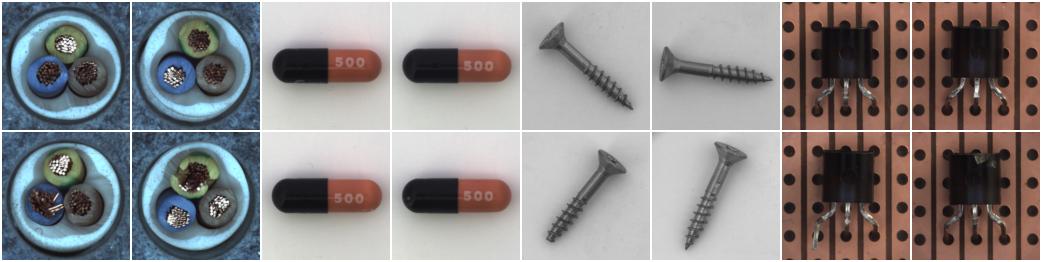

In [6]:
# Tamaños de los splits y ejemplos del set de prueba (vía W&B)
from torchvision.transforms.functional import to_pil_image
from torchvision.utils import make_grid

from src.callbacks import spread_indices

splits = {"train": dm.train_dataset, "val": dm.val_dataset, "test": dm.test_dataset}
sizes = pd.DataFrame({name: pd.Series(Counter(ds.categories)) for name, ds in splits.items()}).loc[CLASSES]
sizes.loc["total"] = sizes.sum()
display(sizes)
print("Test good / defective:", Counter("good" if l == 0 else "defective" for l in dm.test_dataset.labels))

# Examples: first row good, second row defective (2 per class), logged to W&B and shown here
ds = dm.test_dataset
good = [i for i, l in enumerate(ds.labels) if l == 0]
bad = [i for i, l in enumerate(ds.labels) if l == 1]
idx = spread_indices(good, ds.categories, 8) + spread_indices(bad, ds.categories, 8)
grid = make_grid(ds.get_images(idx), nrow=8, padding=2, pad_value=1.0)

dataset_run = start_notebook_run("notebook-dataset")
log_and_show(dataset_run, "dataset/test_examples", image=to_pil_image(grid),
             caption="Fila 1: good. Fila 2: defectuosas (" + ", ".join(ds.defects[i] for i in idx[8:]) + ")")

## 3. Configuración de experimentos con Hydra
Toda la configuración vive en `conf/` y se separa por responsabilidad, de modo que cambiar el modelo, la pérdida o el entrenamiento es solo elegir otro archivo o sobrescribir un valor:

```
conf/
├── config.yaml        # compone un archivo de cada grupo + semilla, nombre de la corrida y el sweep
├── data/mvtec.yaml    # ruta, clases, tamaño de imagen, batch size, split de validación
├── model/
│   ├── vae.yaml       # red (_target_: src.models.vae.VAE), latent_dim (z), β del KL, optimizador
│   └── u-net.yaml     # red (_target_: src.models.unet.UNet), latent_dim, optimizador
├── loss/              # l1.yaml, l2.yaml, ssim.yaml, ssim_l1.yaml (_target_ de cada pérdida)
├── trainer/default.yaml   # argumentos del Trainer de Lightning (épocas, GPU, precisión)
├── trial/                 # conjuntos de hiperparámetros de entrenamiento (base, e200_cos, e200_cos_z256), ver 6.1
└── logger/wandb.yaml      # WandbLogger (proyecto, nombre, tags) y frecuencia de las figuras
```

- La lista `defaults` de `config.yaml` elige la opción de cada grupo (`model: vae`, `loss: l1`, `trial: base`, ...).
- Los archivos de `trial/` usan `# @package _global_`: no son un bloque propio sino que **sobrescriben valores de los otros grupos** (`trainer.max_epochs`, `data.batch_size`), por eso van después de ellos en `defaults`.
- Los bloques con `_target_` se construyen con `hydra.utils.instantiate`, así `train.py` no tiene código específico de cada modelo o pérdida.
- Desde la línea de comandos se puede cambiar un grupo (`model=u-net`), un valor (`model.net.latent_dim=64`, `trainer.max_epochs=50`) o barrer varias opciones con `-m` (multirun).

La celda siguiente compone la configuración con la API de Hydra, igual que lo hace `train.py`.

In [7]:
# Composición de la configuración con Hydra
from hydra import compose, initialize_config_dir
from hydra.utils import instantiate

CONF_DIR = str(ROOT / "conf")


def load_cfg(overrides=()):
    # Compose conf/config.yaml with optional overrides, exactly as `python train.py <overrides>` would
    with initialize_config_dir(config_dir=CONF_DIR, version_base=None):
        return compose(config_name="config", overrides=list(overrides))


cfg = load_cfg()
print(OmegaConf.to_yaml(cfg))

data:
  root: data/mvtec_ad
  classes:
  - cable
  - capsule
  - screw
  - transistor
  img_size: 128
  batch_size: 32
  val_split: 0.15
  num_workers: 0
model:
  name: vae
  beta: 0.001
  net:
    _target_: src.models.vae.VAE
    in_channels: 3
    img_size: ${data.img_size}
    latent_dim: 128
    base_channels: 32
  optimizer:
    _target_: torch.optim.Adam
    _partial_: true
    lr: 0.001
    weight_decay: 0.0
loss:
  name: l1
  fn:
    _target_: torch.nn.L1Loss
trainer:
  _target_: lightning.pytorch.Trainer
  max_epochs: 100
  accelerator: auto
  devices: 1
  precision: 32
  log_every_n_steps: 5
  deterministic: false
  enable_progress_bar: true
  gradient_clip_val: 1.0
logger:
  wandb:
    _target_: lightning.pytorch.loggers.WandbLogger
    project: Autoencoder
    entity: danielpulido-instituto-tecnol-gico-de-costa-rica
    name: ${run_name}
    group: ${model.name}
    tags:
    - ${model.name}
    - ${loss.name}
    mode: online
    log_model: false
    save_dir: ${hydra:runt

Ejemplo de *overrides*: U-Net con SSIM + L1 y espacio latente de 64. Equivale a `python train.py model=u-net loss=ssim_l1 model.net.latent_dim=64`.

In [8]:
# Ejemplo de overrides de Hydra
cfg_example = load_cfg(["model=u-net", "loss=ssim_l1", "model.net.latent_dim=64"])
print(OmegaConf.to_yaml(cfg_example.model))
print(OmegaConf.to_yaml(cfg_example.loss))

name: u-net
beta: 0.0
net:
  _target_: src.models.unet.UNet
  in_channels: 3
  img_size: ${data.img_size}
  latent_dim: 64
  base_channels: 32
optimizer:
  _target_: torch.optim.Adam
  _partial_: true
  lr: 0.001
  weight_decay: 0.0

name: ssim_l1
fn:
  _target_: src.losses.SSIML1Loss
  alpha: 0.85



## 4. Modelos
Ambos modelos reciben imágenes de 3x128x128, devuelven la reconstrucción en [0, 1] (`Sigmoid`) y un vector latente `z` que se usa para el t-SNE. Se entrenan con el mismo `LightningModule` (`src/module.py`), que recibe la red, la pérdida y el optimizador ya construidos por Hydra.

### 4.1 Variational Autoencoder (VAE)
`src/models/vae.py`
- **Encoder:** 4 convoluciones con stride 2 (128 → 64 → 32 → 16 → 8) con BatchNorm y LeakyReLU; el mapa de 256x8x8 se aplana y dos capas lineales producen la media $\mu$ y el log-varianza $\log\sigma^2$ de $q(z|x)$, con $z \in \mathbb{R}^{128}$ (`latent_dim`).
- **Truco de reparametrización:** $z = \mu + \sigma \odot \varepsilon$, $\varepsilon \sim \mathcal{N}(0, I)$, para que el muestreo sea diferenciable. En evaluación se usa $z = \mu$.
- **Decoder:** capa lineal a 256x8x8 y 4 convoluciones transpuestas de vuelta a 128x128.
- **Pérdida:** $\mathcal{L} = \mathcal{L}_{rec}(x, \hat{x}) + \beta \, KL\left(q(z|x) \,\|\, \mathcal{N}(0, I)\right)$ con $\beta = 0.001$. El término KL ordena el espacio latente; un $\beta$ pequeño evita que domine sobre la reconstrucción (imágenes borrosas).

Toda la información tiene que pasar por el cuello de botella de 128 números, por lo que el VAE no puede copiar detalles finos: eso es lo que debería hacer que los defectos no se reconstruyan.

In [9]:
# Construcción y resumen del VAE
from lightning.pytorch.utilities.model_summary import ModelSummary

from src.module import AutoencoderModule


def build_module(cfg):
    # Same construction as train.py: network, loss and optimizer come from the Hydra config
    return AutoencoderModule(
        net=instantiate(cfg.model.net),
        loss_fn=instantiate(cfg.loss.fn),
        optimizer=instantiate(cfg.model.optimizer),
        beta=cfg.model.beta,
    )


def describe(module, x):
    print(ModelSummary(module, max_depth=2))
    with torch.no_grad():
        out = module.eval()(x)
    for key, value in out.items():
        print(f"{key:<7}: {None if value is None else tuple(value.shape)}")


vae_module = build_module(load_cfg(["model=vae"]))
describe(vae_module, x[:4])

  | Name          | Type       | Params | Mode  | FLOPs
-------------------------------------------------------------
0 | net           | VAE        | 7.7 M  | train | 0    
1 | net.encoder   | Sequential | 691 K  | train | 0    
2 | net.fc_mu     | Linear     | 2.1 M  | train | 0    
3 | net.fc_logvar | Linear     | 2.1 M  | train | 0    
4 | net.fc_dec    | Linear     | 2.1 M  | train | 0    
5 | net.decoder   | Sequential | 706 K  | train | 0    
6 | loss_fn       | L1Loss     | 0      | train | 0    
-------------------------------------------------------------
7.7 M     Trainable params
0         Non-trainable params
7.7 M     Total params
30.821    Total estimated model params size (MB)
41        Modules in train mode
0         Modules in eval mode
0         Total Flops
recon  : (4, 3, 128, 128)
z      : (4, 128)
mu     : (4, 128)
logvar : (4, 128)


### 4.2 Autoencoder U-Net
`src/models/unet.py`
- **Encoder:** bloques `DoubleConv` (2 × [conv 3x3 + BatchNorm + ReLU]) con MaxPool entre niveles: 32 → 64 → 128 → 256 canales y un cuello de botella de 128x8x8.
- **Decoder:** convoluciones transpuestas que duplican la resolución y, en cada nivel, **concatenan el mapa del encoder de la misma resolución (*skip connection*)** antes de otro `DoubleConv`.
- **Vector latente:** el promedio global del cuello de botella (128 valores) se usa como `z` para el t-SNE. No hay término KL ($\beta = 0$).

Las *skip connections* dan al decoder acceso directo a los detalles de alta resolución, así que la U-Net reconstruye mucho más nítido que el VAE. El riesgo para detección de anomalías es que también puede "copiar" los defectos a través de las skips, reduciendo la diferencia de error entre imágenes buenas y defectuosas. Esta es una de las hipótesis a revisar en los resultados.

In [10]:
# Construcción y resumen de la U-Net
unet_module = build_module(load_cfg(["model=u-net"]))
describe(unet_module, x[:4])

  | Name           | Type       | Params | Mode  | FLOPs
--------------------------------------------------------------
0 | net            | UNet       | 4.3 M  | train | 0    
1 | net.inc        | DoubleConv | 10.2 K | train | 0    
2 | net.downs      | ModuleList | 1.2 M  | train | 0    
3 | net.bottleneck | Sequential | 442 K  | train | 0    
4 | net.ups        | ModuleList | 303 K  | train | 0    
5 | net.up_convs   | ModuleList | 2.4 M  | train | 0    
6 | net.out        | Sequential | 99     | train | 0    
7 | loss_fn        | L1Loss     | 0      | train | 0    
--------------------------------------------------------------
4.3 M     Trainable params
0         Non-trainable params
4.3 M     Total params
17.087    Total estimated model params size (MB)
83        Modules in train mode
0         Modules in eval mode
0         Total Flops
recon  : (4, 3, 128, 128)
z      : (4, 128)
mu     : None
logvar : None


## 5. Funciones de pérdida
Con $x$ la imagen original y $\hat{x}$ la reconstrucción (ambas en [0, 1]):

| Config | Definición | Qué penaliza |
|---|---|---|
| `l1` | $\frac{1}{N}\sum \lvert x - \hat{x} \rvert$ | error absoluto por píxel; robusta a valores atípicos, tiende a imágenes más nítidas que L2 |
| `l2` | $\frac{1}{N}\sum (x - \hat{x})^2$ | error cuadrático; castiga mucho los errores grandes y tolera los pequeños, lo que suele dar reconstrucciones borrosas |
| `ssim` | $1 - \mathrm{SSIM}(x, \hat{x})$ | diferencias de estructura, contraste y luminancia en ventanas locales (gaussianas 11x11); poco sensible a cambios uniformes de brillo/color |
| `ssim_l1` | $\alpha (1 - \mathrm{SSIM}) + (1 - \alpha) \, L1$, $\alpha = 0.85$ | estructura (SSIM) + fidelidad de intensidad/color (L1) |

L1 y L2 son `torch.nn.L1Loss` / `torch.nn.MSELoss`; SSIM y SSIM + L1 están en `src/losses.py` (con `torchmetrics`).

Para ver qué "le importa" a cada pérdida, la celda siguiente las evalúa entre un batch real y tres versiones alteradas: ruido gaussiano, desenfoque y un cambio de brillo.

In [11]:
# Comparación de las 4 pérdidas ante distintas alteraciones
import torch.nn.functional as F

LOSS_NAMES = ["l1", "l2", "ssim", "ssim_l1"]
loss_fns = {name: instantiate(load_cfg([f"loss={name}"]).loss.fn) for name in LOSS_NAMES}

xb = x[:16]
perturbed = {
    "idéntica": xb,
    "ruido gaussiano (σ = 0.05)": (xb + 0.05 * torch.randn_like(xb)).clamp(0, 1),
    "desenfoque (promedio 5x5)": F.avg_pool2d(xb, 5, stride=1, padding=2, count_include_pad=False),
    "brillo + 0.1": (xb + 0.1).clamp(0, 1),
}
loss_table = pd.DataFrame({name: {loss: fn(p, xb).item() for loss, fn in loss_fns.items()}
                           for name, p in perturbed.items()}).T
display(loss_table.round(4))

,l1,l2,ssim,ssim_l1
idéntica,0.0000,0.0000,0.0000,0.0000
ruido gaussiano (σ = 0.05),0.0397,0.0025,0.4738,0.4087
desenfoque (promedio 5x5),0.0180,0.0012,0.1066,0.0933
brillo + 0.1,0.0990,0.0099,0.0309,0.0411


**Lectura preliminar (completar con la salida):** se espera que L1/L2 castiguen sobre todo el cambio de brillo (desplaza todos los píxeles) y casi nada el desenfoque, mientras que SSIM castigue el ruido y el desenfoque (cambian la estructura local) y muy poco el brillo. Las escalas son distintas, por lo que **los valores de `loss` de corridas con distintas pérdidas no se comparan directamente**; para eso se registran también `l1`, `mse` y `ssim` en todas las corridas.

## 6. Entrenamiento
Cada combinación de **modelo × función de pérdida** (2 × 4 = 8) se entrena con varios **trials**: conjuntos de hiperparámetros de entrenamiento definidos en `conf/trial/`. Dentro de un trial las 8 corridas usan exactamente los mismos hiperparámetros (solo cambian modelo y pérdida), y entre trials se comparan las mismas 8 combinaciones con otro presupuesto de entrenamiento. Así se buscan configuraciones que den buenos resultados en entrenamiento, validación y prueba, y no solo en un único ajuste elegido de antemano.

Todo se controla con Hydra: `train.py` compone la configuración, construye datos, modelo, pérdida, logger y `Trainer`, entrena con `trainer.fit` y evalúa el mejor checkpoint (menor `val/loss`) con `trainer.test`.

Hiperparámetros comunes a todos los trials (de `conf/`):

In [12]:
# Hiperparámetros comunes a todas las corridas (los trials cambian épocas, scheduler del lr y dimensión latente)
hparams = {
    "batch size": cfg.data.batch_size,
    "tamaño de imagen": f"{cfg.data.img_size}x{cfg.data.img_size}x3",
    "validación": f"{cfg.data.val_split:.0%} de train/good por clase",
    "optimizador": f"Adam (lr inicial = {cfg.model.optimizer.lr}, weight decay = {cfg.model.optimizer.weight_decay})",
    "canales base": cfg.model.net.base_channels,
    "β (KL, solo VAE)": cfg.model.beta,
    "gradient clipping": cfg.trainer.gradient_clip_val,
    "precisión": cfg.trainer.precision,
    "semilla": cfg.seed,
}
display(pd.Series(hparams, name="valor").to_frame())

,valor
épocas,100
batch size,32
tamaño de imagen,128x128x3
validación,15% de train/good por clase
optimizador,"Adam (lr = 0.001, weight decay = 0.0)"
dimensión latente z,128
canales base,32
"β (KL, solo VAE)",0.001
precisión,32
semilla,42


### 6.1 Trials (conjuntos de hiperparámetros)
Cada archivo de `conf/trial/` define un trial; con `python train.py trial=e200_cos` se elige uno. Los trials se eligieron a partir de lo que mostraron las 8 corridas `base` (salida de 6.3):

- **No hay sobreajuste, hay subentrenamiento:** en todas las corridas `train/loss ≈ val/loss`, y la mayoría logró su mejor `val/loss` en las últimas épocas (`vae-ssim` en la 100): seguían mejorando. Por eso no se prueban cambios de regularización (weight decay, augmentation) ni de batch size.
- **Con lr constante la `val/loss` oscila al final** (por ejemplo `u-net-ssim_l1`: 0.0032 → 0.0045 → 0.0024 entre las épocas 75, 95 y 100), así que el mejor checkpoint cae en un punto casi al azar de esa oscilación. Bajar el lr al final permite asentarse en un mínimo más bajo.
- **La VAE reconstruye borroso** (SSIM de prueba 0.74–0.84 frente a 0.99 de la U-Net) porque toda la imagen pasa por un vector z de 128 valores. El borde borroso también da error en las imágenes *buenas*, y ese ruido tapa el error de los defectos.

Los dos trials nuevos son **acumulativos**: cada uno agrega un cambio al anterior, de modo que cada comparación aísla un factor (3 trials × 8 = 24 corridas):

| Trial | Cambio | Qué se compara | Motivo |
|---|---|---|---|
| `base` | 100 épocas, lr 1e-3 constante, z 128 | — | las 8 corridas originales |
| `e200_cos` | 200 épocas + lr coseno 1e-3 → 1e-5 | vs `base`: entrenar más y bajar el lr | pasos grandes al inicio y ajuste fino al final: menor pérdida final y sin oscilación |
| `e200_cos_z256` | lo anterior + dimensión latente 256 | vs `e200_cos`: tamaño del cuello de botella | más detalle en la VAE (menos borrosa). En la U-Net `latent_dim` son los canales del cuello de botella de 8x8, que pasan de 128 a 256, los mismos que el último nivel del encoder |

El scheduler coseno (`torch.optim.lr_scheduler.CosineAnnealingLR`) se declara en el trial como `model.scheduler` con `_target_`, igual que el optimizador. El `LightningModule` lo usa si existe y, si no, deja el lr constante. Para agregar un trial nuevo basta con crear otro YAML en `conf/trial/` y sumarlo a `hydra.sweeper.params.trial` en `config.yaml`.

*Expectativa:* en la U-Net, mejor reconstrucción no implica mejor AUROC. Ya reconstruye casi perfecto, incluidos los defectos, por las skip connections. En la VAE, una reconstrucción más nítida de las imágenes buenas sí debería ayudar a separar los defectos.

In [ ]:
# Hiperparámetros efectivos de cada trial (compuestos con Hydra, como los recibe train.py)
TRIALS = OmegaConf.load(ROOT / "conf" / "config.yaml").hydra.sweeper.params.trial.split(",")

rows = []
for trial in TRIALS:
    c = load_cfg([f"trial={trial}"])
    scheduler = c.model.get("scheduler")
    rows.append({
        "trial": trial,
        "épocas": c.trainer.max_epochs,
        "batch size": c.data.batch_size,
        "lr": f"{c.model.optimizer.lr} -> {scheduler.eta_min} (coseno)" if scheduler else f"{c.model.optimizer.lr} (constante)",
        "dimensión latente z": c.model.net.latent_dim,
        "descripción": c.trial.description,
    })
display(pd.DataFrame(rows).set_index("trial"))

Los entrenamientos se lanzan desde aquí ejecutando `train.py` como subproceso (Hydra necesita controlar su propio proceso), y su salida se muestra en vivo en la celda. Para que la salida sea fácil de leer, `run_train` activa el **modo compacto** (`console.verbose=false`, en `conf/config.yaml`):

- se ocultan los avisos de las librerías, el volcado de la configuración y los mensajes de W&B/Lightning (la configuración completa queda igual en `.hydra/config.yaml` y en W&B);
- al iniciar cada corrida se imprime una línea con sus hiperparámetros y el enlace a W&B;
- cada 5 épocas (`console.print_every_n_epochs`), más la primera y la última, una línea con `train/loss`, `val/loss`, `val/ssim`, segundos por época y tiempo restante estimado (`*` = nuevo mejor `val/loss`);
- al terminar, un resumen con duración, mejor época y métricas de prueba (L1, SSIM, AUROC global y por clase);
- al final de la celda, una **tabla con las corridas entrenadas en esa ejecución**, construida con el `results.json` que cada corrida guarda en su carpeta (las corridas saltadas por estar ya hechas no aparecen; la tabla de 6.6 reúne todas).
- las tablas de AUROC muestran la **media de los AUROC por clase** (`*_mean`), la cifra principal (ver 8).

Cada corrida guarda su configuración, logs, `results.json` y checkpoints (`checkpoints/best.ckpt`, `last.ckpt`) en `outputs/<fecha>/<hora>_<corrida>/` (corrida simple) o `multirun/<fecha>/<hora>/<corrida>/` (multirun). Para ver la salida completa de siempre basta con agregar el override `console.verbose=true`.

In [13]:
# Funciones para lanzar train.py, ver su salida en la celda y resumir las corridas
import json
import subprocess
import time

RESULT_COLUMNS = {
    "trial": "trial", "minutes": "minutos", "best_epoch": "mejor época",
    "best_train_loss": "train/loss (mejor época)", "best_val_loss": "mejor val/loss",
    "test/l1": "test L1", "test/ssim": "test SSIM",
    "test/auroc_l1_mean": "AUROC L1", "test/auroc_ssim_mean": "AUROC SSIM", "test/auroc_max_mean": "AUROC max",
}


def collect_results(since=0.0):
    # Table with the results.json of every run finished after `since` (time.time())
    files = [f for d in ("outputs", "multirun") for f in (ROOT / d).glob("**/results.json") if f.stat().st_mtime >= since]
    rows = [json.loads(f.read_text(encoding="utf-8")) for f in sorted(files, key=lambda f: f.stat().st_mtime)]
    if not rows:
        return pd.DataFrame()
    table = pd.DataFrame(rows).set_index("run")
    return table[[c for c in RESULT_COLUMNS if c in table]].rename(columns=RESULT_COLUMNS).round(4)


def run_train(*overrides, multirun=False):
    # Run `python train.py [-m] <overrides>` with the .venv Python, in compact console mode
    cmd = [sys.executable, "train.py", *(["-m"] if multirun else []),
           "trainer.enable_progress_bar=false", "console.verbose=false", *overrides]
    print("$ python", " ".join(cmd[1:]), flush=True)
    env = {**os.environ, "PYTHONUNBUFFERED": "1", "PYTHONUTF8": "1", "HYDRA_FULL_ERROR": "1"}
    started = time.time()
    proc = subprocess.Popen(cmd, cwd=ROOT, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            text=True, encoding="utf-8", errors="replace")
    try:
        for line in proc.stdout:
            print(line, end="", flush=True)
    except KeyboardInterrupt:  # "Interrupt" in the notebook also stops training
        proc.terminate()
        raise
    finally:
        results = collect_results(since=started)  # finished runs are kept even if a later one fails
        if len(results):
            print()
            print(f"Corridas terminadas: {len(results)} | tiempo total: {(time.time() - started) / 60:.1f} min")
            display(results)
    if proc.wait() != 0:
        raise RuntimeError(f"train.py terminó con código {proc.returncode}")

### 6.2 Prueba corta (antes del entrenamiento completo)
3 épocas de cada modelo, con W&B en modo **offline** (no crea corridas en el proyecto) e imprimiendo todas las épocas. Lleva `skip_existing.enabled=false` para ejecutarse siempre, aunque ya exista una prueba anterior igual. Sirve para comprobar que los datos, ambos modelos, las pérdidas SSIM, los callbacks de imágenes/t-SNE y el `test` funcionan antes de lanzar las 8 corridas, y para medir los **segundos por época** con los que se estima la duración total.

In [14]:
# Prueba corta: 3 épocas por modelo (W&B offline)
QUICK = ["trainer.max_epochs=3", "console.print_every_n_epochs=1", "logger.wandb.mode=offline",
         "skip_existing.enabled=false"]  # always run the test, even if an identical one exists
run_train(*QUICK)                                  # vae + l1
run_train("model=u-net", "loss=ssim_l1", *QUICK)   # u-net + ssim_l1

$ python train.py trainer.enable_progress_bar=false console.verbose=false trainer.max_epochs=3 console.print_every_n_epochs=1 logger.wandb.mode=offline

>> vae-l1 | 3 épocas | batch 32 | z 128 | lr 0.001 | W&B offline
vae-l1         epoch   1/3 | train 0.6055 | val 0.2981 | val_ssim 0.453 |  2.2s/época | ETA 0m04s *
vae-l1         epoch   2/3 | train 0.2404 | val 0.2587 | val_ssim 0.495 |  0.9s/época | ETA 0m01s *
vae-l1         epoch   3/3 | train 0.2217 | val 0.1918 | val_ssim 0.574 |  1.4s/época | ETA 0m00s *
OK vae-l1 terminado en 0m50s | mejor época 3 (val/loss 0.1918)
   test: L1 0.0953 | SSIM 0.5720 | AUROC media por clase: L1 0.715 | max 0.540
   AUROC(max) por clase: cable 0.53 capsule 0.66 screw 0.50 transistor 0.47

Corridas terminadas: 1 | tiempo total: 1.0 min


,minutos,mejor época,mejor val/loss,test L1,test SSIM,AUROC L1,AUROC MSE,AUROC SSIM
run,,,,,,,,
vae-l1,0.83,3,0.1918,0.0953,0.572,0.4498,0.4002,0.3998


$ python train.py trainer.enable_progress_bar=false console.verbose=false model=u-net loss=ssim_l1 trainer.max_epochs=3 console.print_every_n_epochs=1 logger.wandb.mode=offline

>> u-net-ssim_l1 | 3 épocas | batch 32 | z 128 | lr 0.001 | W&B offline
u-net-ssim_l1  epoch   1/3 | train 0.1853 | val 0.2004 | val_ssim 0.789 |  4.8s/época | ETA 0m09s *
u-net-ssim_l1  epoch   2/3 | train 0.0488 | val 0.0436 | val_ssim 0.958 |  3.5s/época | ETA 0m04s *
u-net-ssim_l1  epoch   3/3 | train 0.0264 | val 0.0171 | val_ssim 0.983 |  4.1s/época | ETA 0m00s *
OK u-net-ssim_l1 terminado en 0m57s | mejor época 3 (val/loss 0.0171)
   test: L1 0.0181 | SSIM 0.9833 | AUROC media por clase: L1 0.627 | max 0.658
   AUROC(max) por clase: cable 0.49 capsule 0.61 screw 1.00 transistor 0.53

Corridas terminadas: 1 | tiempo total: 1.1 min


,minutos,mejor época,mejor val/loss,test L1,test SSIM,AUROC L1,AUROC MSE,AUROC SSIM
run,,,,,,,,
u-net-ssim_l1,0.95,3,0.0171,0.0181,0.9833,0.4901,0.4855,0.3514


Comprobación visual: las imágenes de la prueba se registraron en W&B en modo offline y quedaron en la carpeta de la corrida. En `val/reconstructions` las filas impares son originales y las pares reconstrucciones; tras solo 3 épocas las reconstrucciones todavía son pobres, lo importante es que **se vean las piezas** (si W&B recibiera mal el rango de la imagen, saldría todo negro).

val/reconstructions (15-33-18_u-net-ssim_l1)


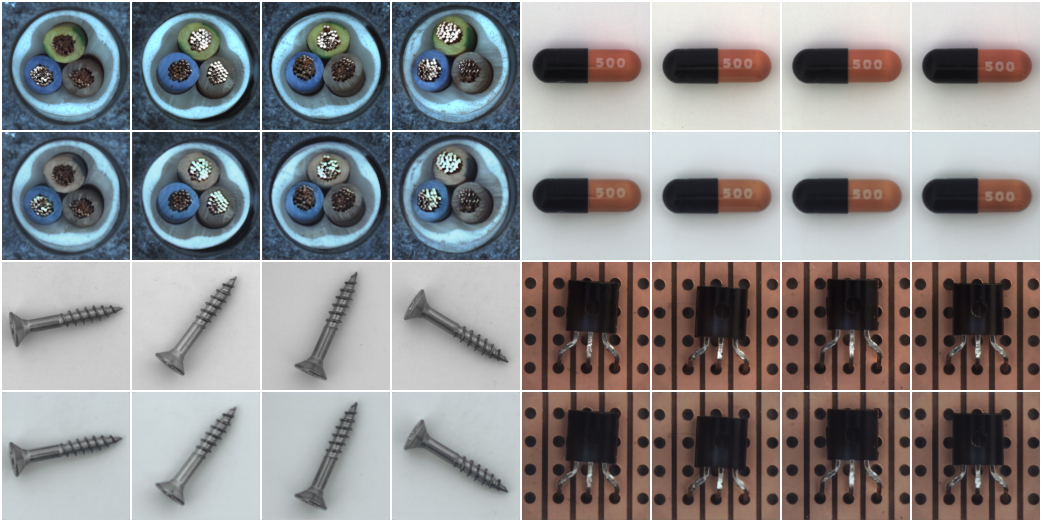

test/reconstructions (15-33-18_u-net-ssim_l1)


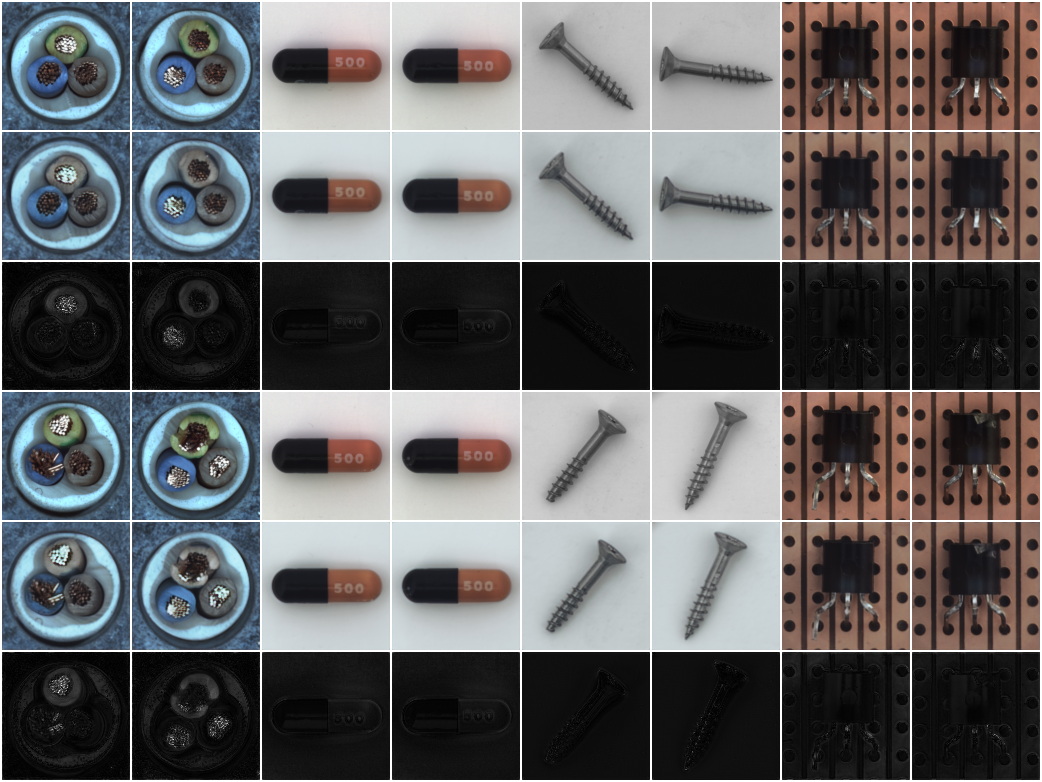

In [15]:
# Verificar las imágenes que W&B guardó en la prueba (deben verse las piezas, no un recuadro negro)
latest = max((ROOT / "outputs").glob("*/*_u-net-ssim_l1*"), key=lambda d: d.stat().st_mtime)
for key in ("val/reconstructions", "test/reconstructions"):
    image = max(latest.glob(f"wandb/*/files/media/images/{key}_*.png"), key=lambda f: f.stat().st_mtime)
    show_image(image, f"{key} ({latest.name})")

### 6.3 Entrenamiento completo: todos los trials con Hydra multirun (sin repetir corridas)
`config.yaml` define el barrido en `hydra.sweeper.params`:

```yaml
hydra:
  sweeper:
    params:
      trial: base,e200_cos,e200_cos_z256
      model: vae,u-net
      loss: l1,l2,ssim,ssim_l1
```

Con `-m`, Hydra ejecuta el producto cartesiano (3 × 2 × 4 = 24 trabajos) **uno tras otro**. `trial` es la primera clave, así que termina las 8 corridas de un trial antes de pasar al siguiente. Equivale a `python train.py -m` en una terminal.

**Corridas ya hechas: se saltan.** Antes de crear la corrida en W&B, `train.py` calcula la **clave del experimento** (`run_key`, en `src/registry.py`). Es un hash de los hiperparámetros que definen la corrida: datos, modelo, pérdida, `Trainer` y semilla. Deja fuera lo que no cambia el resultado: rutas, workers, barra de progreso, modo de W&B y nombres. Después busca:
1. en `outputs/` y `multirun/` un `results.json` con esa clave (solo corridas completas y registradas en W&B online; `results.json` se escribe al final, así que una corrida interrumpida no cuenta);
2. en el proyecto de W&B una corrida **terminada** con esa clave (cubre corridas lanzadas por otro integrante en otra computadora).

Si la encuentra imprime `>> SALTADA <corrida> [clave]: ya existe -> <dónde>` y pasa a la siguiente, sin crear nada en W&B. Las 8 corridas originales (de antes de los trials) tienen la misma clave que el trial `base`, así que ese trial completo se salta. La clave se guarda en `results.json` y en la configuración de cada corrida en W&B. Para forzar un reentrenamiento (por ejemplo, después de cambiar el código de un modelo o una pérdida, que la clave no detecta) se agrega el override `skip_existing.enabled=false`.

**¿Qué pasa al ejecutar las celdas?**
1. La primera muestra el **plan**: cada corrida del barrido, si ya está hecha (y dónde) o pendiente, y el tiempo estimado de las pendientes. No entrena nada.
2. La segunda lanza el barrido. Hydra anuncia cada trabajo (`#0 : trial=base model=vae loss=l1`, ...). Las corridas hechas se saltan en uno o dos segundos (solo crean la carpeta de Hydra) y las pendientes se entrenan en formato compacto: línea de inicio con la clave y el enlace a W&B, una línea cada 5 épocas y un resumen final.
3. Al terminar, la tabla de las corridas entrenadas en esa ejecución.

Cada trabajo es un entrenamiento independiente, con su propia corrida en W&B y su carpeta `multirun/<fecha>/<hora>/<modelo>-<pérdida>-<trial>/` (config, `results.json`, checkpoints `best.ckpt`/`last.ckpt` y archivos de W&B). Si algo falla o se interrumpe, basta con volver a ejecutar la celda: lo terminado se salta y se continúa con lo pendiente.

**Duración estimada (RTX 4060, medida en las corridas `base`):** VAE ≈ 2.5 min y U-Net ≈ 5.7 min por cada 100 épocas con batch 32, o sea ≈ 33 min por cada 8 corridas de 100 épocas. Los dos trials nuevos tienen 200 épocas (≈ 66 min cada uno; con z 256 un poco más), así que las 16 corridas nuevas suman **≈ 2.2 horas**; las 8 de `base` se saltan. Se pueden lanzar por partes con las celdas de 6.4.

Recomendaciones antes de ejecutar: equipo conectado a la corriente y sin suspensión automática, y no ejecutar otras celdas mientras corre (el kernel queda ocupado).

In [ ]:
# Plan del barrido: qué corridas ya están hechas (se saltarán) y cuáles faltan. No entrena nada.
from src.registry import find_existing, local_runs, run_key, wandb_runs

SWEEP = OmegaConf.load(ROOT / "conf" / "config.yaml").hydra.sweeper.params
MINUTES_PER_100_EPOCHS = {"vae": 2.5, "u-net": 5.7}  # measured in the base runs (batch 32, RTX 4060)


def show_plan(trials=None, models=None, losses=None):
    # One row per run of the sweep, with its run_key and whether it is already done (local or W&B)
    local = local_runs(ROOT)
    try:
        remote = wandb_runs(WANDB_PROJECT, WANDB_ENTITY)
    except Exception as error:  # no connection: only outputs/ and multirun/ are checked
        print("No se pudo consultar W&B, solo se revisa outputs/ y multirun/:", error)
        remote = {}
    rows = []
    for trial in trials or SWEEP.trial.split(","):
        for model in models or SWEEP.model.split(","):
            for loss in losses or SWEEP.loss.split(","):
                c = load_cfg([f"trial={trial}", f"model={model}", f"loss={loss}"])
                done = find_existing(c, ROOT, local=local, remote=remote)
                minutes = MINUTES_PER_100_EPOCHS[model] * c.trainer.max_epochs / 100 * (1.5 if c.data.batch_size < 32 else 1)
                rows.append({"corrida": c.run_name, "clave": run_key(c), "estado": "hecha" if done else "pendiente",
                             "min estimados": 0 if done else round(minutes, 1), "dónde": done or ""})
    table = pd.DataFrame(rows).set_index("corrida")
    pending = table[table.estado == "pendiente"]
    print(f"{len(table)} corridas: {len(table) - len(pending)} hechas (se saltan), {len(pending)} pendientes "
          f"(≈ {pending['min estimados'].sum() / 60:.1f} h) -> W&B {WANDB_ENTITY}/{WANDB_PROJECT}")
    with pd.option_context("display.max_rows", 100, "display.max_colwidth", 120):
        display(table)
    return table


plan = show_plan()

In [16]:
# ENTRENAMIENTO COMPLETO: todos los trials x 2 modelos x 4 pérdidas (las corridas ya hechas se saltan)
run_train(multirun=True)

Plan: 8 corridas x 100 épocas -> W&B danielpulido-instituto-tecnol-gico-de-costa-rica/Autoencoder
      vae-l1, vae-l2, vae-ssim, vae-ssim_l1, u-net-l1, u-net-l2, u-net-ssim, u-net-ssim_l1
$ python train.py -m trainer.enable_progress_bar=false console.verbose=false
[2026-11-03 15:45:25,609][HYDRA] Launching 8 jobs locally
[2026-11-03 15:45:25,609][HYDRA] 	#0 : model=vae loss=l1 trainer.enable_progress_bar=False console.verbose=False

>> vae-l1 | 100 épocas | batch 32 | z 128 | lr 0.001 | W&B online
   https://forge.coreweave.com/wandb/danielpulido-instituto-tecnol-gico-de-costa-rica/Autoencoder/runs/ic8fvwcj
vae-l1         epoch   1/100 | train 0.6044 | val 0.2770 | val_ssim 0.471 |  2.2s/época | ETA 3m36s *
vae-l1         epoch   5/100 | train 0.1672 | val 0.1532 | val_ssim 0.647 |  1.0s/época | ETA 1m50s *
vae-l1         epoch  10/100 | train 0.1063 | val 0.0964 | val_ssim 0.722 |  1.4s/época | ETA 1m37s *
vae-l1         epoch  15/100 | train 0.0927 | val 0.0830 | val_ssim 0.743 |  1

,minutos,mejor época,mejor val/loss,test L1,test SSIM,AUROC L1,AUROC MSE,AUROC SSIM
run,,,,,,,,
vae-l1,2.66,91,0.0451,0.0403,0.7860,0.3558,0.3870,0.3913
vae-l2,1.95,95,0.0106,0.0566,0.7375,0.3847,0.4086,0.3920
vae-ssim,2.63,100,0.1671,0.0420,0.8359,0.3681,0.4104,0.4563
vae-ssim_l1,2.59,94,0.1531,0.0401,0.8321,0.3487,0.3903,0.4567
u-net-l1,5.49,82,0.0065,0.0064,0.9912,0.3637,0.3623,0.5135
u-net-l2,5.49,84,0.0001,0.0051,0.9927,0.3547,0.3681,0.4948
u-net-ssim,5.97,96,0.0016,0.0042,0.9984,0.5614,0.5093,0.5017
u-net-ssim_l1,5.99,86,0.0023,0.0044,0.9980,0.5257,0.5040,0.4991


### 6.4 Lanzar por partes o repartir entre integrantes
Un override en la línea de comandos reemplaza esa clave del barrido. Así se puede entrenar **un solo trial** (por ejemplo, si no hay tiempo para las ~2 horas seguidas) o repartir trials entre integrantes. Como las corridas hechas se saltan también si están en W&B, no importa si dos personas lanzan por error la misma parte: la segunda saltará lo que la primera ya terminó (salvo que ambas lo entrenen **al mismo tiempo**, porque la revisión ocurre al inicio de cada corrida). Repartir requiere el mismo commit del repo, el dataset en `data/mvtec_ad/` y la sesión de W&B propia.

`show_plan(...)` acepta las mismas listas para revisar solo una parte antes de lanzarla.

In [ ]:
# Alternativa: entrenar solo una parte (o la parte asignada a este integrante)
# Ejemplos (descomentar UNA línea):
# show_plan(trials=["e200_cos"])                                     # ver el plan de un trial antes de lanzarlo
# run_train("trial=e200_cos", multirun=True)                         # 8 corridas: un trial completo
# run_train("trial=e200_cos_z256", multirun=True)                    # 8 corridas: el otro trial
# run_train("trial=e200_cos,e200_cos_z256", "model=vae", multirun=True)  # 8 corridas: VAE en los dos trials nuevos
# run_train("model=vae", multirun=True)                              # VAE con las 4 pérdidas, en todos los trials

### 6.5 (Opcional) Repetir una sola corrida
Una corrida suelta también pasa por la revisión de 6.3: si el experimento ya existe se salta. Para **repetirlo** de verdad (por ejemplo, después de cambiar el código) se agrega `skip_existing.enabled=false`; en ese caso quedan dos corridas del mismo experimento en W&B, y las secciones 7-9 toman la **más reciente** de cada combinación modelo/pérdida/trial.

In [ ]:
# (Opcional) Repetir una sola corrida
# run_train("model=u-net", "loss=ssim", "trial=e200")                              # se salta si ya existe
# run_train("model=u-net", "loss=ssim", "trial=e200", "skip_existing.enabled=false")  # fuerza el reentrenamiento

### 6.6 Resultados de todas las corridas (locales)
Tabla con el `results.json` de cada corrida completa guardada en esta computadora (la más reciente de cada experimento), para comparar los trials sin esperar a W&B. Las corridas de otros integrantes no aparecen aquí; la comparación completa, desde W&B, está en 9.2. Las pérdidas de entrenamiento y validación solo son comparables **entre trials de la misma combinación modelo/pérdida** (cada pérdida tiene su propia escala); `test L1`, `test SSIM` y los AUROC sí se comparan entre todas.

In [ ]:
# Todas las corridas locales completas, agrupadas por modelo/pérdida para comparar sus trials
local_results = pd.DataFrame(local_runs(ROOT).values())
if "trial" not in local_results:  # every run is from before the trials existed
    local_results["trial"] = "base"
local_results["trial"] = local_results["trial"].fillna("base")
local_results = local_results.drop_duplicates(["model", "loss", "trial"])  # newest per combination
columns = [c for c in RESULT_COLUMNS if c in local_results and c != "trial"]
table = (local_results.set_index(["model", "loss", "trial"])[columns].rename(columns=RESULT_COLUMNS)
         .sort_index().round(4))
with pd.option_context("display.max_rows", 100):
    display(table)

## 7. Seguimiento de los entrenamientos en W&B
> **Base preliminar:** las celdas de las secciones 7-9 se escribieron antes de tener las corridas; se ajustarán cuando existan.

Las secciones 7 y 8 analizan las 8 corridas (2 modelos × 4 pérdidas) de **un trial**, elegido con `TRIAL` en la celda siguiente; la comparación entre trials está en 9.2. Desde aquí todo se obtiene de W&B con su API (`src/wandb_utils.py`): curvas, imágenes y figuras de t-SNE registradas durante el entrenamiento, y la tabla de errores del set de prueba. Las figuras nuevas que se construyen con esos datos se registran en la corrida `notebook-analysis` antes de mostrarse.

In [ ]:
# Obtener de W&B las 8 corridas del trial que se analiza en las secciones 7 y 8
from src import wandb_utils as wu

TRIAL = "base"  # trial analysed in 7-8 (e.g. the best one according to 9.2)

runs = wu.get_runs(WANDB_PROJECT, WANDB_ENTITY, trial=TRIAL)
for (model, loss), run in sorted(runs.items()):
    print(f"{model:<6} {loss:<8} {run.name:<24} {run.url}")
assert len(runs) == 8, f"Se esperaban 8 corridas terminadas del trial {TRIAL}, hay {len(runs)}"

analysis_run = start_notebook_run(f"notebook-analysis-{TRIAL}")

### 7.1 Pérdida de entrenamiento y validación
Para cada modelo, las curvas de `train/loss` y `val/loss` de sus 4 corridas. Como cada corrida optimiza una pérdida distinta, las curvas sirven para ver **convergencia y sobreajuste** (separación train/val), no para decidir cuál es mejor; para eso, la segunda figura compara métricas comunes (`val/l1`, `val/mse`, `val/ssim`) en la misma escala.

In [ ]:
# Curvas de train/val loss por modelo
for model in wu.MODELS:
    log_and_show(analysis_run, f"curves/{model}_loss", fig=wu.loss_curves_figure(runs, model))

In [ ]:
# Métricas comunes de validación (L1, MSE, SSIM) por modelo
for model in wu.MODELS:
    fig = wu.loss_curves_figure(runs, model, keys=("val/l1", "val/mse", "val/ssim"))
    log_and_show(analysis_run, f"curves/{model}_common_metrics", fig=fig)

**Análisis (TODO):** velocidad de convergencia de cada pérdida, estabilidad, diferencia train/val, y qué pérdida logra mejor `val/ssim` y `val/l1` en cada modelo.

### 7.2 Reconstrucciones del set de validación (16 imágenes)
Imágenes registradas por `ReconstructionCallback` (filas impares: originales, filas pares: reconstrucciones), siempre las mismas 16 imágenes (4 por clase). Se muestran la primera y la última época de cada corrida.

In [ ]:
# Reconstrucciones de validación: primera y última época
for model in wu.MODELS:
    for loss in wu.LOSSES:
        history = wu.image_history(runs[(model, loss)], "val/reconstructions")
        for epoch, path in [history[0], history[-1]]:
            show_image(path, f"{model} / {loss} - época {epoch}")

**Análisis (TODO):** nitidez y fidelidad de color por modelo y pérdida (se espera VAE más borroso, U-Net casi idéntica a la entrada), y clases más difíciles (p. ej. *screw*, *cable*).

### 7.3 Espacio latente con t-SNE (validación, a lo largo de las épocas)
`LatentTSNECallback` proyecta con t-SNE el vector latente de todas las imágenes de validación cada 10 épocas, coloreado por clase. Primero la evolución de una corrida, luego la última época de todas.

In [ ]:
# Evolución del t-SNE de validación de una corrida
TSNE_RUN = ("vae", "ssim_l1")  # run whose evolution is shown

for step, fig in wu.plotly_history(runs[TSNE_RUN], "val/tsne"):
    fig.show()

In [ ]:
# t-SNE de validación de la última época de cada corrida
for model in wu.MODELS:
    for loss in wu.LOSSES:
        fig = wu.last_plotly(runs[(model, loss)], "val/tsne")
        fig.update_layout(title=f"{model} / {loss} - " + (fig.layout.title.text or ""))
        fig.show()

**Análisis (TODO):** si las 4 clases se separan en grupos, desde qué época, y diferencias entre el latente del VAE (regularizado por el KL) y el de la U-Net (promedio del cuello de botella).

## 8. Evaluación del modelo
La evaluación usa el set de prueba completo con el mejor checkpoint de cada corrida. El **error de reconstrucción** de cada imagen se usa como puntaje de anomalía: si el modelo solo aprendió lo normal, las imágenes defectuosas deberían tener mayor error.

### 8.1 Reconstrucción de imágenes buenas y con anomalías (16 imágenes de prueba)
`TestReconstructionCallback`: filas 1-3 son 8 imágenes buenas (original, reconstrucción, mapa de error $|x - \hat{x}|$) y filas 4-6 son 8 defectuosas. El mapa de error comparte la misma escala en ambas mitades.

In [ ]:
# Reconstrucciones del set de prueba (good vs defectuosas)
for model in wu.MODELS:
    for loss in wu.LOSSES:
        show_image(wu.last_image(runs[(model, loss)], "test/reconstructions"), f"{model} / {loss} - set de prueba")

t-SNE del set de prueba (verde = good, rojo = defective; el símbolo indica la clase):

In [ ]:
# t-SNE del set de prueba (good vs defective)
for model in wu.MODELS:
    for loss in wu.LOSSES:
        fig = wu.last_plotly(runs[(model, loss)], "test/tsne")
        fig.update_layout(title=f"{model} / {loss} - " + (fig.layout.title.text or ""))
        fig.show()

**Análisis (TODO):** ¿el mapa de error se concentra en el defecto?, ¿la reconstrucción "corrige" el defecto (deseable) o lo copia (U-Net)?, ¿se separan good y defective en el latente?

### 8.2 Histogramas del error de reconstrucción
A partir de la tabla `test/scores` (error por imagen) se construyen, por clase, histogramas del error de las imágenes **good** contra **cada tipo de defecto**. Cuanto menos se solapen, mejor separa el modelo ese defecto. Se grafican para la mejor corrida de cada modelo (mayor AUROC); cambiando `HIST_RUNS` y `SCORE` se pueden ver las demás.

In [ ]:
# Histogramas del error: good vs cada tipo de defecto
SCORE = "score_l1"  # score_l1 | score_mse | score_ssim
auroc_key = "test/auroc_" + SCORE.removeprefix("score_")

best = {model: max(wu.LOSSES, key=lambda l: runs[(model, l)].summary.get(auroc_key, 0)) for model in wu.MODELS}
HIST_RUNS = [(model, loss) for model, loss in best.items()]
print("Corridas para los histogramas:", HIST_RUNS)

scores = {key: wu.load_table(run) for key, run in runs.items()}  # test/scores of every run (used again in 9)

for model, loss in HIST_RUNS:
    for category in CLASSES:
        fig = wu.error_histograms(scores[(model, loss)], category, SCORE, title_prefix=f"{model} / {loss} - ")
        log_and_show(analysis_run, f"histograms/{model}_{loss}/{category}", fig=fig)

**Análisis (TODO):** qué defectos se detectan bien (defectos grandes: `missing_cable`, `misplaced`, ...) y cuáles se solapan con las imágenes buenas (defectos pequeños: `scratch_neck`, `poke`, ...).

## 9. Comparación entre configuraciones
### 9.1 Modelos y funciones de pérdida (trial `TRIAL`)
Resumen de las 8 corridas del trial analizado con métricas en la misma escala:
- `val/*`: valor de la última época en validación (solo imágenes buenas).
- `test/l1`, `test/ssim`: calidad de reconstrucción en todo el set de prueba (mejor checkpoint).
- `test/auroc_*`: qué tan bien el error de reconstrucción separa good de defective (0.5 = azar, 1 = perfecto).

In [ ]:
# Tabla comparativa de las 8 corridas
keys = ["val/l1", "val/mse", "val/ssim", "test/l1", "test/ssim", "test/auroc_l1", "test/auroc_mse", "test/auroc_ssim"]
comparison = pd.DataFrame(wu.summary_table(runs, keys)).set_index(["model", "loss"]).drop(columns="run")
analysis_run.log({"comparison/summary": wandb.Table(dataframe=comparison.reset_index())})
display(comparison.round(4))

In [ ]:
# AUROC por clase, modelo y pérdida
import plotly.express as px

per_class = pd.DataFrame(wu.summary_table(runs, [f"{auroc_key}/{c}" for c in CLASSES])).drop(columns="run")
per_class = per_class.melt(id_vars=["model", "loss"], var_name="clase", value_name="auroc")
per_class["clase"] = per_class["clase"].str.split("/").str[-1]

fig = px.bar(per_class, x="clase", y="auroc", color="loss", barmode="group", facet_col="model",
             color_discrete_map=wu.LOSS_COLORS, title=f"AUROC por clase ({SCORE})", template="plotly_white")
fig.add_hline(y=0.5, line_dash="dot")
log_and_show(analysis_run, "comparison/auroc_per_class", fig=fig)

Error medio de reconstrucción en imágenes **correctas** vs **defectuosas** por configuración. Un buen detector tiene error bajo en las buenas y una razón defectuosas/buenas alta.

In [ ]:
# Error medio good vs defective por configuración
rows = []
for (model, loss), table in sorted(scores.items()):
    for category, (mean_good, mean_bad) in wu.good_vs_defective_means(table, SCORE).items():
        rows.append({"model": model, "loss": loss, "clase": category,
                     "error good": mean_good, "error defective": mean_bad, "razón def/good": mean_bad / mean_good})
errors = pd.DataFrame(rows)
display(errors[errors.clase == "all"].set_index(["model", "loss"]).drop(columns="clase").round(4))

long = errors[errors.clase == "all"].melt(id_vars=["model", "loss"], value_vars=["error good", "error defective"],
                                          var_name="tipo", value_name="error")
fig = px.bar(long, x="loss", y="error", color="tipo", barmode="group", facet_col="model",
             color_discrete_map={"error good": "#2ca02c", "error defective": "#d62728"},
             title=f"Error medio de reconstrucción ({SCORE}): good vs defective", template="plotly_white")
log_and_show(analysis_run, "comparison/good_vs_defective", fig=fig)

**Análisis (TODO):** mejor modelo/pérdida para *reconstruir* (val/test SSIM, L1) vs mejor para *detectar anomalías* (AUROC); no tienen por qué coincidir. Relacionar con las reconstrucciones de 7.2 y 8.1 y con los histogramas de 8.2.

### 9.2 Comparación entre trials
Las mismas 8 combinaciones con cada conjunto de hiperparámetros, desde W&B (incluye las corridas de todos los integrantes). Para cada combinación modelo/pérdida se compara:
- **entrenamiento y validación:** `train/loss` y `val/loss` de la última época (misma pérdida, así que son comparables entre trials de la misma fila). Una `val/loss` mucho mayor que la `train/loss` indica sobreajuste.
- **prueba:** `test/l1` y `test/ssim` (calidad de reconstrucción) y `test/auroc_max_mean` (detección de anomalías).

El mejor trial de cada combinación se elige por **AUROC max** (objetivo de la tarea: separar good de defective); también se muestra cuál reconstruye mejor (`test/ssim`) por si no coinciden.

In [ ]:
# Comparación de trials: entrenamiento, validación y prueba de cada combinación modelo/pérdida
all_runs = wu.get_all_runs(WANDB_PROJECT, WANDB_ENTITY)
trial_keys = ["train/loss", "val/loss", "test/l1", "test/ssim", "test/auroc_l1_mean", "test/auroc_max_mean"]
trials_cmp = pd.DataFrame(wu.trials_table(all_runs, trial_keys)).set_index(["model", "loss", "trial"]).drop(columns="run")
analysis_run.log({"comparison/trials": wandb.Table(dataframe=trials_cmp.reset_index())})
with pd.option_context("display.max_rows", 100):
    display(trials_cmp.round(4))

# Best trial of each model/loss: by anomaly detection (AUROC max) and by reconstruction (test SSIM)
flat = trials_cmp.reset_index()
best_trials = pd.DataFrame({
    "mejor trial (AUROC max)": flat.loc[flat.groupby(["model", "loss"])["test/auroc_max_mean"].idxmax()].set_index(["model", "loss"])["trial"],
    "AUROC max": flat.groupby(["model", "loss"])["test/auroc_max_mean"].max(),
    "mejor trial (test SSIM)": flat.loc[flat.groupby(["model", "loss"])["test/ssim"].idxmax()].set_index(["model", "loss"])["trial"],
    "test SSIM": flat.groupby(["model", "loss"])["test/ssim"].max(),
})
display(best_trials.round(4))

fig = px.bar(flat, x="loss", y="test/auroc_max_mean", color="trial", barmode="group", facet_col="model",
             title="AUROC max (media por clase) por trial", template="plotly_white")
fig.add_hline(y=0.5, line_dash="dot")
log_and_show(analysis_run, "comparison/trials_auroc", fig=fig)

In [ ]:
# Cerrar la corrida de análisis en W&B
analysis_run.finish()

## 10. Conclusiones
TODO (completar con los resultados). Puntos a cubrir:
1. **VAE vs U-Net:** calidad de reconstrucción vs capacidad de detectar defectos; efecto de las *skip connections*.
2. **Funciones de pérdida:** cuál converge mejor, cuál da reconstrucciones más nítidas y cuál separa mejor good/defective (L1 vs L2 vs SSIM vs SSIM + L1).
3. **Por clase y por defecto:** qué objetos y tipos de defecto son fáciles o difíciles, según los histogramas.
4. **Espacio latente:** qué muestra el t-SNE sobre lo aprendido (clases bien separadas, good vs defective).
5. **Limitaciones y mejoras:** resolución 128x128 (defectos pequeños se pierden), pocas épocas/datos, β del VAE, usar SSIM por regiones o mapas de error para localizar defectos.